# Imports

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score, auc
from sklearn.metrics import roc_curve, auc, precision_recall_curve, f1_score, average_precision_score
import matplotlib.pyplot as plt

# load the input data

## load OneHotEncoding as y

In [10]:
import ast
OHE_train=pd.read_csv("data/OHE_train_dataset_All_Food_6_shortend_recat.csv", sep=';')
OHE_test=pd.read_csv("data/OHE_test_dataset_All_Food_6_shortend_recat.csv", sep=';')

y_train = np.array([
    np.array(ast.literal_eval(f), dtype=int)
    for f in OHE_train['OneHotEncoding']
])
y_test = np.array([
    np.array(ast.literal_eval(f), dtype=int)
    for f in OHE_test['OneHotEncoding']
])

## load Mordred as x

In [11]:
x_input="Mordred_shortend-correlation_95"
X_train_index=pd.read_csv(f'Mordred_train_dataset_shortend-correlation_95_All_Food_6.csv', sep=',') #for RFECV dataset use: Mordred_RFECV_roc_auc_test_dataset.csv
X_test_index=pd.read_csv(f'Mordred_test_dataset_shortend-correlation_95_All_Food_6.csv', sep=',')#for RFECV dataset use: Mordred_RFECV_roc_auc_train_dataset.csv
X_test=np.delete(X_test_index, 0,1)
X_train=np.delete(X_train_index, 0,1)

# ML models

## optimized RandomForest

In [12]:
from sklearn.ensemble import RandomForestClassifier
classifier="RF"
number_e = 1100
min_samples_l=3

min_samples_s=7


RFCLassifier=RandomForestClassifier(random_state=42, n_estimators=number_e, min_samples_leaf=min_samples_l, min_samples_split=min_samples_s)
RFCLassifier.fit(X_train, y_train)
y_scores_RF=RFCLassifier.predict_proba(X_test)
y_pred_RF=RFCLassifier.predict(X_test)


pd.DataFrame(np.transpose(np.array(RFCLassifier.predict_proba(X_test))[:, :, 1])).to_csv(f"{x_input}_{classifier}_{number_e}_{min_samples_l}_{min_samples_s}_predict_proba.csv", sep=";", index=False)
pd.DataFrame(RFCLassifier.predict(X_test)).to_csv(f"{x_input}_{classifier}_{number_e}_{min_samples_l}_{min_samples_s}_predict.csv", sep=";", index=False)
   

## optimized CatBoost

In [17]:
from catboost import CatBoostClassifier
from sklearn.multiclass import OneVsRestClassifier
classifier="Cat"
learning=0.01
dep=7
# Wrap CatBoost inside OneVsRest
Cat = OneVsRestClassifier(CatBoostClassifier(
n_estimators=1000,
depth=dep,
learning_rate=learning,
loss_function='Logloss',  # for binary classification per label
random_seed=42, 
verbose=True
))
Cat.fit(X_train, y_train)
y_scores_Cat=Cat.predict_proba(X_test)

y_pred_Cat=Cat.predict(X_test)


    
pd.DataFrame(Cat.predict_proba(X_test)).to_csv(f"{x_input}_{classifier}_{learning}_{dep}_predict_proba.csv", sep=";", index=False)
pd.DataFrame(Cat.predict(X_test)).to_csv(f"{x_input}_{classifier}_{learning}_{dep}_predict.csv", sep=";", index=False)

0:	learn: 0.6712269	total: 121ms	remaining: 2m 1s
1:	learn: 0.6474429	total: 221ms	remaining: 1m 50s
2:	learn: 0.6276419	total: 316ms	remaining: 1m 45s
3:	learn: 0.6076825	total: 450ms	remaining: 1m 52s
4:	learn: 0.5888267	total: 542ms	remaining: 1m 47s
5:	learn: 0.5703927	total: 614ms	remaining: 1m 41s
6:	learn: 0.5528063	total: 693ms	remaining: 1m 38s
7:	learn: 0.5351011	total: 753ms	remaining: 1m 33s
8:	learn: 0.5201051	total: 819ms	remaining: 1m 30s
9:	learn: 0.5044364	total: 899ms	remaining: 1m 29s
10:	learn: 0.4891143	total: 988ms	remaining: 1m 28s
11:	learn: 0.4720442	total: 1.08s	remaining: 1m 28s
12:	learn: 0.4576716	total: 1.16s	remaining: 1m 28s
13:	learn: 0.4443208	total: 1.25s	remaining: 1m 27s
14:	learn: 0.4295211	total: 1.34s	remaining: 1m 27s
15:	learn: 0.4166732	total: 1.43s	remaining: 1m 28s
16:	learn: 0.4043779	total: 1.51s	remaining: 1m 27s
17:	learn: 0.3928394	total: 1.59s	remaining: 1m 26s
18:	learn: 0.3813812	total: 1.68s	remaining: 1m 26s
19:	learn: 0.3698352	to

# ROC and PR-curve 

Mordred_shortend-correlation_95 RandomForest ROC AUC: 0.9051
Mordred_shortend-correlation_95 RandomForest PR AUC: 0.3751
Mordred_shortend-correlation_95 RandomForest avg_precision: 0.3753
Mordred_shortend-correlation_95 CatBoost ROC AUC: 0.9006
Mordred_shortend-correlation_95 CatBoost PR AUC: 0.3879
Mordred_shortend-correlation_95 CatBoost avg_precision: 0.3882


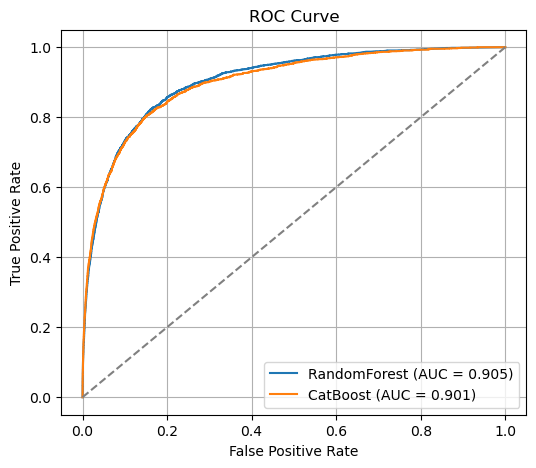

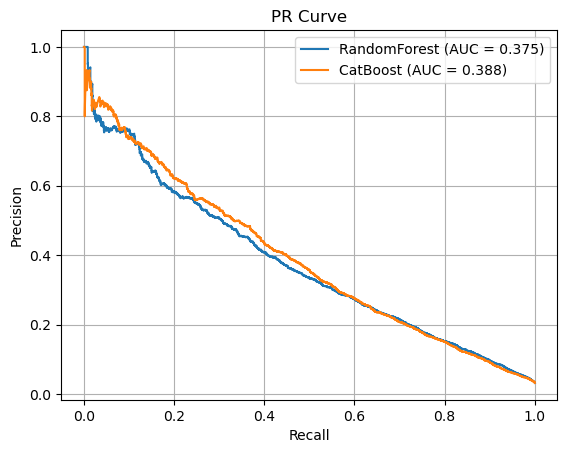

In [18]:
OHE=pd.read_csv("data/OpenPOM_test_dataset_All_Food_6_shortend_recat.csv")
OHE=OHE.drop(['SMILES'], axis=1)
OHE_num=OHE.to_numpy().flatten()


plt.figure(1, figsize=(6, 5))
files=[f"Mordred_shortend-correlation_95_RF_1100_3_7_predict_proba.csv", "Mordred_shortend-correlation_95_Cat_0.01_7_predict_proba.csv"]# input previously generated csv files
labels=["RandomForest","CatBoost"]

#---------------------------

y_score_RF=[]
fpr_RF=[]
tpr_RF=[]
roc_auc_RF=[]
avg_precision_RF=[]
avg_precision_RF_micro=[]
PR_auc_RF=[]
precision_RF=[]
recall_RF=[]
f1_RF=[]
f1_RF_micro=[]

for i, file in enumerate(files):

    my_data = np.genfromtxt(file, delimiter=';')#
    results=my_data[1:].flatten()
 

    fprRFC, tprRFC, _ = roc_curve(OHE_num, results)
    fpr_RF.append(fprRFC)
    tpr_RF.append(tprRFC)
    roc_auc_RF.append(auc(fprRFC, tprRFC))

    precisionRFC, recallRFC, _ = precision_recall_curve(OHE_num, results) 
    precision_RF.append(precisionRFC)
    recall_RF.append(recallRFC)

    avg_precision_RF_micro.append(average_precision_score(OHE_num, results, average="micro"))
    PR_auc_RF.append(auc(recall_RF[i],precision_RF[i]))


    print(f'{x_input} {labels[i]} ROC AUC: {roc_auc_RF[i]:.4f}')
    print(f'{x_input} {labels[i]} PR AUC: {PR_auc_RF[i]:.4f}')

    print(f'{x_input} {labels[i]} avg_precision: {avg_precision_RF_micro[i]:.4f}')


    plt.figure(1)
    plt.plot(fpr_RF[i], tpr_RF[i], label=f'{labels[i]} (AUC = {roc_auc_RF[i]:.3f})')




plt.figure(1)
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'ROC Curve')
plt.legend(loc="lower right")
plt.grid()
plt.savefig(f"ROC_{x_input}_{labels[i]}.png")
plt.show()
for i, file in enumerate(files):
    plt.figure(2)
    plt.plot(recall_RF[i], precision_RF[i], label=f'{labels[i]} (AUC = {PR_auc_RF[i]:.3f})')
# 7️⃣ Plot PR curve
plt.figure(2, figsize=(6, 5))
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title(f'PR Curve')
plt.legend(loc="upper right")
plt.grid()
plt.savefig(f"PR_{x_input}_{labels[i]}.png")
plt.show()